In [3]:
# Install required libraries 
# !pip install pandas openpyxl matplotlib ta

import pandas as pd  # For data manipulation
import numpy as np   # For numerical operations
import matplotlib.pyplot as plt  # For plotting charts
from ta.volatility import BollingerBands  # For Bollinger Bands


In [2]:
!pip install ta

  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for ta: filename=ta-0.11.0-py3-none-any.whl size=29422 sha256=f210268b7ad558dad90e04af975db3821ca7be82204e773770471420212b73d6
  Stored in directory: c:\users\user\appdata\local\pip\cache\wheels\a1\d7\29\7781cc5eb9a3659d032d7d15bdd0f49d07d2b24fec29f44bc4
Successfully built ta


In [4]:
# Define the path to your Excel file
excel_path = "C:/Users/User/Downloads/Historical prices.xlsx"

# Get the sheet names (each sheet corresponds to a company's data)
company_names = pd.ExcelFile(excel_path).sheet_names

# Initialize an empty dictionary to store each company's data
data_dict = {}


In [6]:
# Verify the sheet names in your Excel file
excel_path = "C:/Users/User/Downloads/Historical prices.xlsx"
sheet_names = pd.ExcelFile(excel_path).sheet_names
print(sheet_names)


['Sheet1', 'Sheet2', 'Sheet3', 'Sheet4', 'Sheet5', 'Sheet6', 'Sheet7']


In [7]:
# Display the available keys in data_dict to avoid KeyError
print("Available keys in data_dict:", data_dict.keys())

# Access the data dynamically based on the actual sheet name
first_key = list(data_dict.keys())[0]  # Get the first company as an example
data_dict[first_key].head()  # Display the first few rows


Available keys in data_dict: dict_keys(['Sheet1', 'Sheet2', 'Sheet3', 'Sheet4', 'Sheet5', 'Sheet6', 'Sheet7'])


,Date,Open,High,Low,Close,Adjusted,Change,Volume,log_return
2514,2014-10-09,25.39,25.60,25.15,25.26,22.42,0.0022,309506100,NaN
2513,2014-10-10,25.17,25.51,25.08,25.18,22.36,-0.0029,265326368,-0.003172
2512,2014-10-13,25.33,25.45,24.95,24.95,22.16,-0.0091,214333472,-0.009176
2511,2014-10-14,25.10,25.13,24.64,24.69,21.92,-0.0106,254754248,-0.010476
2510,2014-10-15,24.49,24.79,23.80,24.39,21.65,-0.0123,403734400,-0.012225


In [8]:
# Define the path to your Excel file
excel_path = "C:/Users/User/Downloads/Historical prices.xlsx"

# Load sheet names (since they are 'Sheet1', 'Sheet2', etc.)
sheet_names = pd.ExcelFile(excel_path).sheet_names
print("Sheet Names:", sheet_names)

# Print the first few rows from each sheet to identify the companies
for sheet in sheet_names:
    print(f"Preview of {sheet}:")
    df = pd.read_excel(excel_path, sheet_name=sheet)
    print(df.head(3))  # Print the first 3 rows for preview


Sheet Names: ['Sheet1', 'Sheet2', 'Sheet3', 'Sheet4', 'Sheet5', 'Sheet6', 'Sheet7']
Preview of Sheet1:
        Date    Open    High     Low   Close  Adjusted  Change    Volume
0 2024-10-07  224.50  225.69  221.33  221.69    221.69 -0.0225  38980161
1 2024-10-04  227.90  228.00  224.13  226.80    226.80   0.005  37345098
2 2024-10-03  225.14  226.81  223.32  225.67    225.67 -0.0049  34044158
Preview of Sheet2:
        Date    Open    High     Low   Close  Adjusted  Change    Volume
0 2024-10-07  416.00  417.11  409.00  409.54    409.54 -0.0157  19558359
1 2024-10-04  418.24  419.75  414.97  416.06    416.06 -0.0012  19190913
2 2024-10-03  417.63  419.55  414.29  416.54    416.54 -0.0014  13686421
Preview of Sheet3:
        Date   Open   High    Low  Close  Adjusted  Change    Volume
0 2024-10-07  22.40  22.65  22.02  22.38     22.38 -0.0093  54687214
1 2024-10-04  22.70  22.91  22.30  22.59     22.59  0.0148  49966930
2 2024-10-03  22.14  22.73  21.65  22.26     22.26 -0.0058  49565931

In [9]:
# Map sheet names to company names (you can adjust this based on your data)
sheet_to_company = {
    'Sheet1': 'Microsoft',
    'Sheet2': 'Apple',
    'Sheet3': 'Pepsico',
    'Sheet4': 'Intel',
    'Sheet5': 'Walmart',
    'Sheet6': 'Company6',  # Replace with actual names
    'Sheet7': 'Company7'
}

# Initialize a dictionary to store the data
data_dict = {}

# Load the data and calculate log returns for each company
for sheet, company in sheet_to_company.items():
    df = pd.read_excel(excel_path, sheet_name=sheet).sort_values(by='Date')
    df['log_return'] = np.log(df['Close'] / df['Close'].shift(1))  # Calculate log return
    data_dict[company] = df  # Store in dictionary using company name

# Display the first few rows of Microsoft as an example
data_dict['Microsoft'].head()


,Date,Open,High,Low,Close,Adjusted,Change,Volume,log_return
2514,2014-10-09,25.39,25.60,25.15,25.26,22.42,0.0022,309506100,NaN
2513,2014-10-10,25.17,25.51,25.08,25.18,22.36,-0.0029,265326368,-0.003172
2512,2014-10-13,25.33,25.45,24.95,24.95,22.16,-0.0091,214333472,-0.009176
2511,2014-10-14,25.10,25.13,24.64,24.69,21.92,-0.0106,254754248,-0.010476
2510,2014-10-15,24.49,24.79,23.80,24.39,21.65,-0.0123,403734400,-0.012225


In [10]:
# Initialize lists to store performance metrics
performance = []

# Calculate mean and standard deviation of log returns for each company
for company, df in data_dict.items():
    mean_log_return = df['log_return'].mean()
    sd_log_return = df['log_return'].std()
    performance.append([company, mean_log_return, sd_log_return])

# Create a performance DataFrame
performance_df = pd.DataFrame(performance, columns=['Company', 'Mean_Log_Return', 'SD_Log_Return'])
performance_df


,Company,Mean_Log_Return,SD_Log_Return
0,Microsoft,0.000864,0.017981
1,Apple,0.000871,0.017101
2,Pepsico,-0.000162,0.022517
3,Intel,0.000231,0.011772
4,Walmart,0.000443,0.013341
5,Company6,0.000763,0.013642
6,Company7,0.002247,0.030461


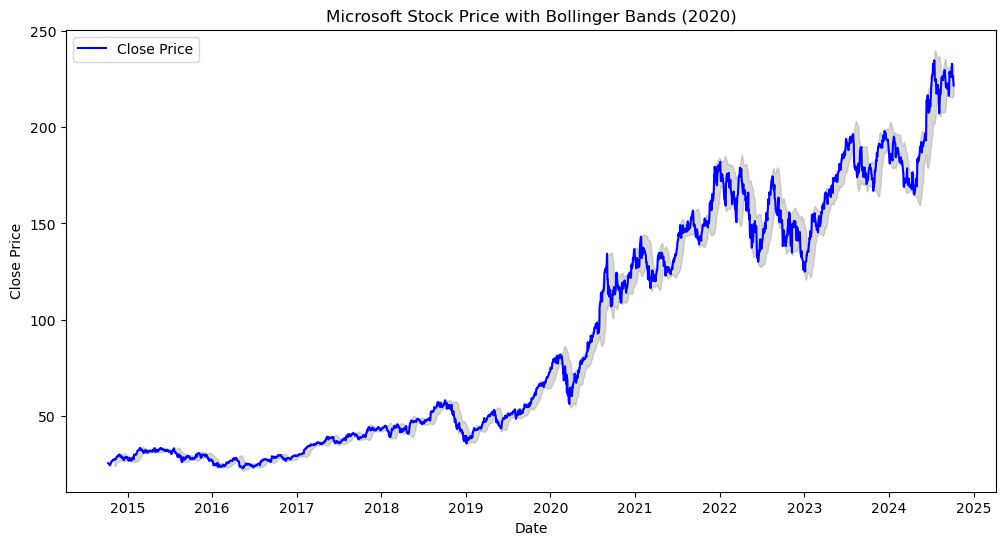

In [11]:
# Example with Microsoft data
df_microsoft = data_dict['Microsoft']

# Calculate Bollinger Bands
indicator_bb = BollingerBands(close=df_microsoft['Close'], window=20, window_dev=2)
df_microsoft['bb_upper'] = indicator_bb.bollinger_hband()
df_microsoft['bb_lower'] = indicator_bb.bollinger_lband()

# Plot Bollinger Bands
plt.figure(figsize=(12, 6))
plt.plot(df_microsoft['Date'], df_microsoft['Close'], label='Close Price', color='blue')
plt.fill_between(df_microsoft['Date'], df_microsoft['bb_lower'], df_microsoft['bb_upper'], color='gray', alpha=0.3)
plt.title('Microsoft Stock Price with Bollinger Bands (2020)')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.show()


In [12]:
# Combine log returns from all companies into a single DataFrame
log_returns = pd.DataFrame({company: df['log_return'] for company, df in data_dict.items()})

# Calculate the correlation matrix (ignoring NaN values)
correlation_matrix = log_returns.corr()
correlation_matrix


,Microsoft,Apple,Pepsico,Intel,Walmart,Company6,Company7
Microsoft,1.000000,0.682911,0.487026,0.429993,0.312839,0.482145,0.546522
Apple,0.682911,1.000000,0.543618,0.464957,0.337657,0.511185,0.605462
Pepsico,0.487026,0.543618,1.000000,0.343515,0.263939,0.375066,0.482650
Intel,0.429993,0.464957,0.343515,1.000000,0.474112,0.487084,0.251862
Walmart,0.312839,0.337657,0.263939,0.474112,1.000000,0.545922,0.213964
Company6,0.482145,0.511185,0.375066,0.487084,0.545922,1.000000,0.398754
Company7,0.546522,0.605462,0.482650,0.251862,0.213964,0.398754,1.000000


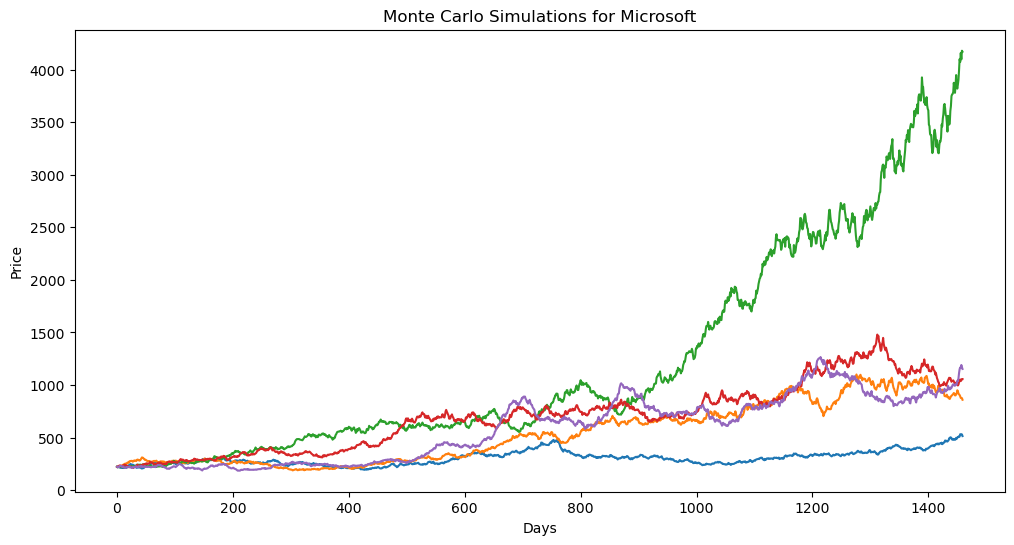

In [13]:
np.random.seed(123)  # For reproducibility
n_days = 365 * 4  # 4 years
n_sim = 300  # Number of simulations

# Get mean and standard deviation of Microsoft log returns
mu = performance_df.loc[performance_df['Company'] == 'Microsoft', 'Mean_Log_Return'].values[0]
sigma = performance_df.loc[performance_df['Company'] == 'Microsoft', 'SD_Log_Return'].values[0]

# Run Monte Carlo simulations
simulations = np.zeros((n_days, n_sim))
last_price = df_microsoft['Close'].iloc[-1]

for sim in range(n_sim):
    prices = [last_price]
    for day in range(1, n_days):
        growth_rate = np.exp(np.random.normal(mu, sigma))
        prices.append(prices[-1] * growth_rate)
    simulations[:, sim] = prices

# Plot the first few simulations
plt.figure(figsize=(12, 6))
plt.plot(simulations[:, :5])
plt.title('Monte Carlo Simulations for Microsoft')
plt.xlabel('Days')
plt.ylabel('Price')
plt.show()


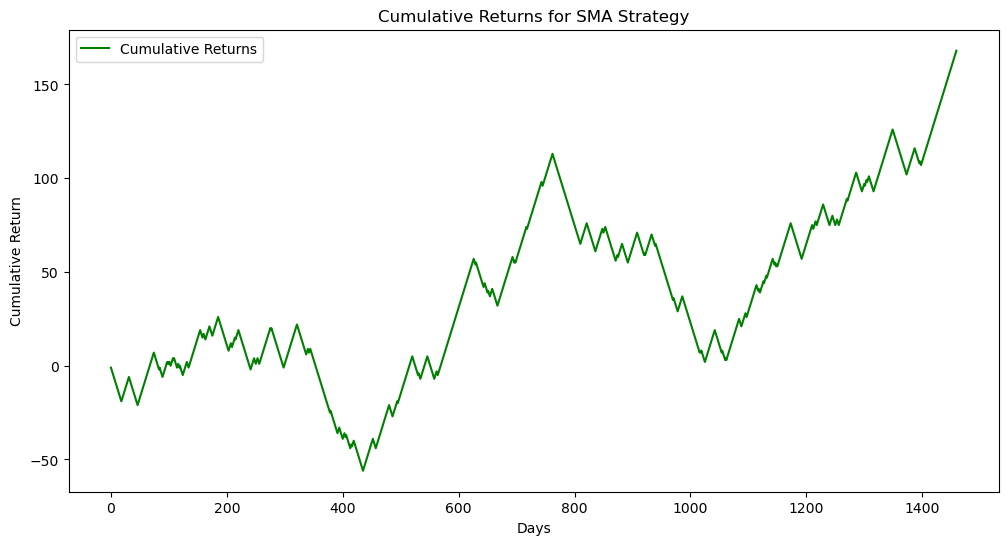

In [14]:
# Define an SMA strategy function
def sma_strategy(prices, window=20):
    sma = prices.rolling(window=window).mean()
    signals = np.where(prices > sma, 1, -1)  # 1 = Buy, -1 = Sell
    return signals

# Apply the strategy to the first simulation
prices = pd.Series(simulations[:, 0])
signals = sma_strategy(prices)

# Calculate cumulative returns
cumulative_returns = np.cumsum(signals)

# Plot cumulative returns
plt.figure(figsize=(12, 6))
plt.plot(cumulative_returns, label='Cumulative Returns', color='green')
plt.title('Cumulative Returns for SMA Strategy')
plt.xlabel('Days')
plt.ylabel('Cumulative Return')
plt.legend()
plt.show()
